# 02 — Pré-processamento e injeção de anomalias

Fase 3 do plano. Todo o código está em `src/` (`data.py`, `inject.py`, `preprocess.py`); este notebook executa,
verifica e documenta. As decisões abaixo vêm das EDAs (`01_eda.ipynb` e `01b_eda_nab.ipynb`).

| Decisão | Por quê |
|---|---|
| **Divisão temporal** (70/30 no Alibaba e no Google; 15/85 no NAB), sem embaralhar | Métricas vizinhas no tempo são quase iguais (autocorrelação de 0,8 a 0,99). Numa divisão aleatória, cada ponto de teste teria um "gêmeo" no treino e as métricas sairiam otimistas. No NAB, os 15 % iniciais são o período probatório do próprio benchmark, sem rótulos. |
| **Injeção diferente no treino e no teste** | Se o Random Forest for testado com o mesmo tipo e magnitude de anomalia que viu no treino, mede-se memorização. O teste tem magnitudes e durações em faixas mais largas e dois tipos que o treino não tem (vazamento de memória e queda de CPU). |
| **Magnitude em desvios padrão robustos** (1,4826 × MAD do treino) | Uma mesma configuração vale para CPU em %, memória normalizada e bytes de rede. O MAD não é inflado pelos picos já existentes, ao contrário do desvio padrão. Exceção: quedas de CPU usam fração do valor corrente (30–60 %), porque em desvios padrão a CPU média do cluster chegaria a zero, o que é irrealista e fácil demais de detectar. |
| **Injeção só em pontos "normais"** | Como prometido no artigo: os eventos não caem em janelas sinalizadas (cobertura baixa) nem em pontos já extremos (\|z robusto\| > 3). |
| **30 repetições da injeção** com sementes diferentes | O teste do Alibaba tem só 673 janelas (2,3 dias). Uma única injeção daria 1 ou 2 eventos por tipo. Com 30, a fase 4 reporta média e desvio padrão. |
| **Features de contexto horário** (seno e cosseno da hora) | A EDA mostrou ciclo diário forte. Sem a hora, o pico de CPU normal das 6 h parece anomalia e uma alta de CPU de madrugada parece normal. |
| **`net_in`/`net_out` só como variação** (diferença de 1ª ordem) no Alibaba | A série bruta é uma rampa crescente ao longo do trace. Com divisão temporal, todo o teste ficaria acima de qualquer valor do treino. |
| **log1p no NAB** | Os valores variam várias ordens de grandeza (bytes, contagens). Sem o log, poucos picos dominam a escala. |
| **StandardScaler dentro do Pipeline do modelo** (fase 4), não aqui | Se o scaler fosse ajustado antes, a validação cruzada do GridSearchCV usaria estatísticas das dobras de validação: vazamento. |

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import data
from src.preprocess import (ALIBABA, GOOGLE, NAB, REPETICOES, ROTULOS_TIPO, SEED, alibaba_cobertura_baixa,
                            injetar_trechos, preparar_alibaba, preparar_google, preparar_nab)

FIG_DIR = ROOT / "results" / "figures"
TAB_DIR = ROOT / "results" / "tables"
PROC = ROOT / "data" / "processed"

COR = {"alibaba": "#2a78d6", "google": "#eb6834", "nab": "#1baf7a"}
CINZA = "#52514e"
ORIGINAL = "#b5b4ae"
DESTAQUE = "#e4e3df"
COLS_META = ["treino", "rotulo", "tipo_anomalia", "evento_id", "excluir", "n_maquinas", "serie"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "lines.linewidth": 1.0,
    "xtick.color": CINZA, "ytick.color": CINZA,
})
pd.set_option("display.width", 160)


def br(x, casas=None):
    txt = f"{x:g}" if casas is None else f"{x:.{casas}f}"
    return txt.replace(".", ",")


def features_de(tab):
    return [c for c in tab.columns if c not in COLS_META]

## 1. Tipos de anomalia injetados

In [2]:
linhas = []
for exp in (ALIBABA, GOOGLE, NAB):
    for trecho, cfg in (("treino", exp.injecao_treino), ("teste", exp.injecao_teste)):
        if cfg is None:
            linhas.append({"dataset": exp.nome, "trecho": trecho, "tipo": "rótulos reais do NAB"})
            continue
        for t in cfg.tipos:
            linhas.append({
                "dataset": exp.nome, "trecho": trecho, "tipo": t.nome, "colunas": ", ".join(t.colunas),
                "forma": t.forma, "sinal": "+" if t.sinal > 0 else "−",
                "duração (janelas de 5 min)": f"{t.duracao[0]}–{t.duracao[1]}",
                "magnitude": (f"{br(t.magnitude[0])}–{br(t.magnitude[1])} σ robusto" if t.unidade == "sigma"
                              else f"{t.magnitude[0]:.0%}–{t.magnitude[1]:.0%} do valor".replace(".", ",")),
            })
tipos = pd.DataFrame(linhas).fillna("")
tipos.to_csv(TAB_DIR / "tab_prep_tipos_anomalia.csv", index=False)
tipos

,dataset,trecho,tipo,colunas,forma,sinal,duração (janelas de 5 min),magnitude
0,alibaba,treino,pico_cpu,cpu_util_percent,pico,+,1–3,3–5 σ robusto
1,alibaba,treino,memoria_sustentada,mem_util_percent,patamar,+,6–24,2–4 σ robusto
2,alibaba,treino,rajada_rede,"net_in, net_out",pico,+,2–6,3–5 σ robusto
3,alibaba,teste,pico_cpu,cpu_util_percent,pico,+,1–3,2–6 σ robusto
4,alibaba,teste,memoria_sustentada,mem_util_percent,patamar,+,4–36,"1,5–5 σ robusto"
5,alibaba,teste,rajada_rede,"net_in, net_out",pico,+,1–8,2–6 σ robusto
6,alibaba,teste,vazamento_memoria,mem_util_percent,rampa,+,12–48,2–5 σ robusto
7,alibaba,teste,queda_cpu,cpu_util_percent,patamar,−,6–18,30%–60% do valor
8,google,treino,pico_cpu,avg_cpu,pico,+,1–3,3–5 σ robusto
9,google,treino,memoria_sustentada,avg_mem,patamar,+,6–24,2–4 σ robusto


In [3]:
cfg = ALIBABA.injecao_treino
print(f"Fração-alvo de janelas anômalas por repetição: {cfg.fracao_alvo:.0%}")
print(f"Espaço mínimo entre eventos: {cfg.espaco_minimo} janelas ({cfg.espaco_minimo * 5} min)")
print(f"Pontos candidatos: |z robusto| <= {cfg.z_max_candidato} nas colunas afetadas")
print(f"Repetições: {REPETICOES}; sementes: {SEED} + 1000·r (treino) e {SEED} + 1000·r + 1 (teste)")

Fração-alvo de janelas anômalas por repetição: 5%
Espaço mínimo entre eventos: 12 janelas (60 min)
Pontos candidatos: |z robusto| <= 3.0 nas colunas afetadas
Repetições: 30; sementes: 42 + 1000·r (treino) e 42 + 1000·r + 1 (teste)


## 2. Execução da repetição 0 e divisão temporal

In [4]:
TABELAS, EVENTOS = {}, {}
for nome, f in (("alibaba", preparar_alibaba), ("google", preparar_google), ("nab", preparar_nab)):
    TABELAS[nome], EVENTOS[nome] = f(0)

def resumo_divisao(nome, tab):
    tr, te = tab[tab["treino"]], tab[~tab["treino"]]
    dur = lambda t: (len(t) * 5) / (60 * 24)
    return {"dataset": nome, "janelas treino": len(tr), "janelas teste": len(te),
            "dias treino (aprox.)": round(dur(tr), 1), "dias teste (aprox.)": round(dur(te), 1),
            "% anômalo treino": 100 * tr["rotulo"].mean(), "% anômalo teste": 100 * te["rotulo"].mean(),
            "janelas sinalizadas": int(tab["excluir"].sum()), "features": len(features_de(tab))}

divisao = pd.DataFrame([resumo_divisao(n, t) for n, t in TABELAS.items()]).round(1)
divisao

,dataset,janelas treino,janelas teste,dias treino (aprox.),dias teste (aprox.),% anômalo treino,% anômalo teste,janelas sinalizadas,features
0,alibaba,1570,673,5.5,2.3,5.7,5.8,4,7
1,google,5644,2420,19.6,8.4,5.2,5.7,0,5
2,nab,13455,76334,46.7,265.0,5.8,10.7,0,4


No NAB os números somam as 19 séries. O teste do NAB tem ~11 % de pontos "anômalos" porque usa as janelas
oficiais, que são largas (EDA do NAB). Por isso a avaliação no NAB será por evento (fase 4), não ponto a ponto.

## 3. Como fica uma série com anomalias injetadas

Trecho de teste do Alibaba, repetição 0. Em cinza, a série original; em azul, a série com as anomalias.

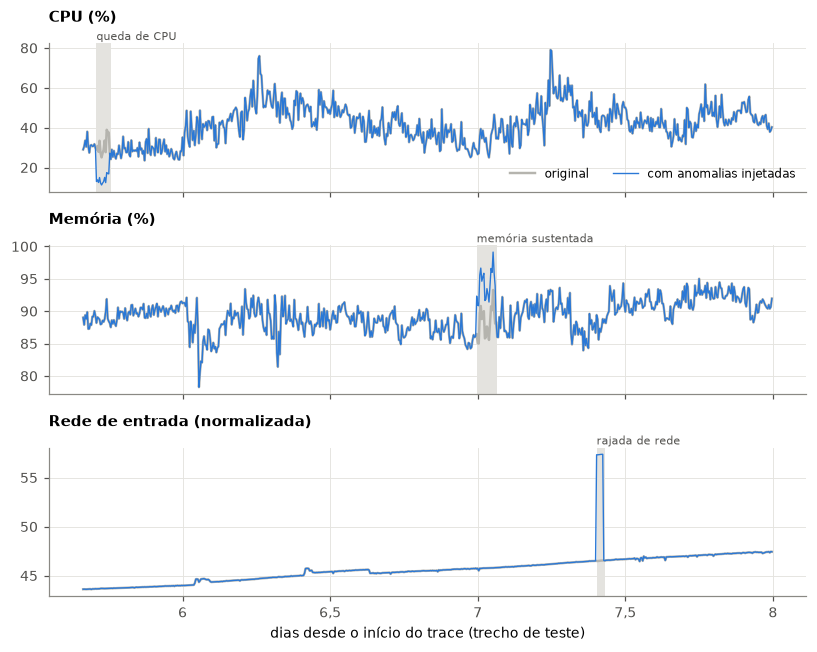

In [5]:
orig = data.load_alibaba()
ev = EVENTOS["alibaba"].query("trecho == 'teste'")
bruto, marcacao, _, mask_tr = injetar_trechos(ALIBABA, orig, excluir=alibaba_cobertura_baixa(), repeticao=0)
assert marcacao["rotulo"].equals(TABELAS["alibaba"]["rotulo"])
df_te = bruto[~mask_tr]
PAINEIS = [("cpu_util_percent", "CPU (%)"), ("mem_util_percent", "Memória (%)"), ("net_in", "Rede de entrada (normalizada)")]

dias = orig.index[~mask_tr] / pd.Timedelta(days=1)
fig, axes = plt.subplots(3, 1, figsize=(7.5, 6), sharex=True)
for ax, (col, titulo) in zip(axes, PAINEIS):
    ax.plot(dias, orig.loc[~mask_tr, col], color=ORIGINAL, linewidth=1.6, label="original")
    ax.plot(dias, df_te[col], color=COR["alibaba"], linewidth=0.9, label="com anomalias injetadas")
    ax.set_title(titulo, pad=14)
    for _, e in ev.iterrows():
        if col not in e["colunas"].split(","):
            continue
        x0 = dias[e["posicao"]]
        x1 = dias[min(e["posicao"] + e["duracao"], len(dias) - 1)]
        ax.axvspan(x0, x1 + 5 / 1440, color=DESTAQUE, linewidth=0, zorder=0)
        ax.annotate(ROTULOS_TIPO[e["tipo"]], xy=(x0, 1), xycoords=("data", "axes fraction"),
                    xytext=(0, 2), textcoords="offset points", fontsize=7.5, color=CINZA)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v)))
axes[0].legend(frameon=False, fontsize=8, loc="lower right", ncols=2)
axes[-1].set_xlabel("dias desde o início do trace (trecho de teste)")
axes[-1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: br(round(v, 2))))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_prep_injecao_alibaba.png")
plt.show()

## 4. Verificações

Cada `assert` abaixo falha se a regra correspondente for violada.

In [6]:
for nome, tab in TABELAS.items():
    ev = EVENTOS[nome]
    # 1. nenhuma anomalia injetada em janela sinalizada
    assert tab.loc[tab["excluir"], "rotulo"].sum() == 0
    # 2. rótulos e eventos batem
    sint = tab[tab["tipo_anomalia"].ne("") & tab["tipo_anomalia"].ne("real")]
    chave = ["serie", "trecho", "evento_id"] if nome == "nab" else ["trecho", "evento_id"]
    assert len(sint) == ev["duracao"].sum()
    # 3. eventos não se sobrepõem e respeitam o espaço mínimo
    for _, g in ev.groupby([c for c in chave if c != "evento_id"]):
        g = g.sort_values("posicao")
        fim_ant = (g["posicao"] + g["duracao"]).shift()
        assert (g["posicao"].iloc[1:] - fim_ant.iloc[1:] >= ALIBABA.injecao_treino.espaco_minimo).all()
    # 4. sem valores ausentes
    assert not tab[features_de(tab)].isna().any().any()
    # 5. reprodutibilidade
    f = {"alibaba": preparar_alibaba, "google": preparar_google, "nab": preparar_nab}[nome]
    tab2, ev2 = f(0)
    assert tab2.equals(tab) and ev2.equals(ev)
    print(f"{nome}: ok")

# 6. treino e teste têm configurações diferentes
for exp in (ALIBABA, GOOGLE):
    tr = {t.nome: t for t in exp.injecao_treino.tipos}
    te = {t.nome: t for t in exp.injecao_teste.tipos}
    print(f"{exp.nome}: tipos só no teste = {sorted(set(te) - set(tr))}; "
          f"faixas diferentes = {sorted(n for n in tr if tr[n] != te[n])}")

alibaba: ok
google: ok


nab: ok
alibaba: tipos só no teste = ['queda_cpu', 'vazamento_memoria']; faixas diferentes = ['memoria_sustentada', 'pico_cpu', 'rajada_rede']
google: tipos só no teste = ['queda_cpu', 'vazamento_memoria']; faixas diferentes = ['memoria_sustentada', 'pico_cpu']


## 5. Eventos ao longo das 30 repetições

In [7]:
linhas_ev, linhas_cont = [], []
for nome, f in (("alibaba", preparar_alibaba), ("google", preparar_google), ("nab", preparar_nab)):
    for r in range(REPETICOES):
        tab, ev = f(r)
        linhas_ev.append(ev.assign(dataset=nome, repeticao=r))
        cont = tab.groupby("treino")["rotulo"].mean()
        linhas_cont.append({"dataset": nome, "repeticao": r,
                            "treino": cont.get(True), "teste": cont.get(False)})

eventos_rep = pd.concat(linhas_ev, ignore_index=True)
por_tipo = (eventos_rep.groupby(["dataset", "trecho", "tipo"])
            .agg(eventos=("evento_id", "size"), duracao_media=("duracao", "mean"),
                 magnitude_media=("magnitude", "mean"), unidade=("unidade", "first"))
            .round(2))
por_tipo.to_csv(TAB_DIR / "tab_prep_eventos_por_tipo.csv")
por_tipo

eventos  duracao_media  magnitude_media unidade
dataset trecho tipo                                                               
alibaba teste  memoria_sustentada       21          19.81             3.30   sigma
               pico_cpu                 13           1.77             4.26   sigma
               queda_cpu                16          14.25             0.46  fracao
               rajada_rede              19           4.16             3.73   sigma
               vazamento_memoria        22          27.59             3.22   sigma
        treino memoria_sustentada      128          14.82             3.05   sigma
               pico_cpu                115           1.96             4.08   sigma
               rajada_rede             118           4.00             4.08   sigma
google  teste  memoria_sustentada       64          17.80             3.37   sigma
               pico_cpu                 65           1.97             3.99   sigma
               queda_cpu                61          11.89             0.44  fracao
               vazamento_memoria        68          29.59             3.57   sigma
        treino memoria_sustentada      516          14.73             3.05   sigma
               pico_cpu                507           2.04             3.98   sigma
nab     treino patamar                1697          11.66             3.05   sigma
               pico                   2038           1.94             4.48   sigma

In [8]:
contaminacao = pd.DataFrame(linhas_cont).groupby("dataset")[["treino", "teste"]].agg(["mean", "min", "max"])
(100 * contaminacao).round(1)

treino           teste            
          mean  min  max  mean   min   max
dataset                                   
alibaba    5.5  5.0  6.4   6.7   5.1  10.8
google     5.1  5.0  5.3   5.5   5.0   6.4
nab        5.9  5.3  6.7  10.7  10.7  10.7

A fração de janelas anômalas fica perto da meta de 5 % em cada repetição. O último evento pode ultrapassar um
pouco a meta, e no teste do Alibaba, que é curto, um evento longo pesa mais. No NAB o teste não aparece porque
usa os rótulos reais.

## 6. Features e normalização

As features de cada dataset estão abaixo. A tabela seguinte mostra o que acontece quando o `StandardScaler` é
ajustado só no treino e aplicado ao teste. Média ≠ 0 e desvio padrão ≠ 1 no teste indicam deriva entre os
períodos, que os modelos vão enfrentar como enfrentariam em produção.

In [9]:
for nome, tab in TABELAS.items():
    print(f"{nome}: {features_de(tab)}")

alibaba: ['cpu_util_percent', 'mem_util_percent', 'disk_io_percent', 'net_in_diff', 'net_out_diff', 'hora_sin', 'hora_cos']
google: ['avg_cpu', 'avg_mem', 'avg_assigned_mem', 'hora_sin', 'hora_cos']
nab: ['value', 'value_diff', 'hora_sin', 'hora_cos']


In [10]:
deriva = []
for nome in ("alibaba", "google"):
    tab = TABELAS[nome]
    X = tab[features_de(tab)]
    normal = tab["rotulo"].eq(0) & ~tab["excluir"]
    sc = StandardScaler().fit(X[tab["treino"]])
    Z = pd.DataFrame(sc.transform(X[~tab["treino"] & normal]), columns=X.columns)
    deriva.append(pd.DataFrame({"dataset": nome, "média no teste": Z.mean(), "desvio no teste": Z.std()}))
deriva = pd.concat(deriva).round(2)
deriva.to_csv(TAB_DIR / "tab_prep_deriva_treino_teste.csv")
deriva

,dataset,média no teste,desvio no teste
cpu_util_percent,alibaba,0.22,0.90
mem_util_percent,alibaba,0.58,0.85
disk_io_percent,alibaba,-0.03,0.87
net_in_diff,alibaba,-0.01,0.42
net_out_diff,alibaba,-0.01,0.41
hora_sin,alibaba,-0.26,1.04
hora_cos,alibaba,0.09,0.96
avg_cpu,google,0.08,1.02
avg_mem,google,-0.09,1.13
avg_assigned_mem,google,0.30,1.11


**Leitura:** valores próximos de média 0 e desvio 1 indicam que o teste (só pontos normais) se parece com o
treino. Desvios grandes em alguma feature significam que, sem nenhuma anomalia injetada, o teste já está fora do
padrão do treino. Isso tende a gerar falsos positivos e precisa ser discutido nos resultados.

## 7. Arquivos gerados

A repetição 0 de cada dataset é gravada em `data/processed/` para inspeção. As demais repetições não são gravadas:
são geradas de forma determinística pela fase 4 a partir das sementes. A configuração completa vai para um JSON.

In [11]:
for nome, tab in TABELAS.items():
    tab.to_csv(PROC / f"{nome}_rep0.csv")
    EVENTOS[nome].to_csv(PROC / f"{nome}_rep0_eventos.csv", index=False)

config = {"seed": SEED, "repeticoes": REPETICOES,
          "experimentos": {e.nome: e.to_dict() for e in (ALIBABA, GOOGLE, NAB)}}
(PROC / "config_preprocessamento.json").write_text(json.dumps(config, indent=2, ensure_ascii=False, default=str))
sorted(p.name for p in PROC.iterdir())

['alibaba_falhas_por_janela.csv',
 'alibaba_machine_usage_300s_com_timestamp.csv',
 'alibaba_rep0.csv',
 'alibaba_rep0_eventos.csv',
 'config_preprocessamento.json',
 'google_rep0.csv',
 'google_rep0_eventos.csv',
 'nab_rep0.csv',
 'nab_rep0_eventos.csv']

## 8. Pendências para a fase 4

- **GridSearchCV:** validação cruzada temporal (`TimeSeriesSplit`) sobre o treino com anomalias injetadas,
  excluindo janelas sinalizadas da pontuação; regra única de otimização entre F1 e FPR.
- **Avaliação no NAB por evento:** janela detectada se houver ≥ 1 alarme dentro dela; falso positivo = alarme fora
  de qualquer janela.
- **Repetições:** treinar e avaliar em cada uma das 30 repetições; reportar média e desvio padrão, e recall por
  tipo de anomalia.
- **Deriva treino/teste** (seção 6): discutir no texto, e considerar uma variante com contexto adicional se as
  taxas de falsos positivos ficarem dominadas por ela.